# Question 2 — Breast Cancer Classification using an MLP built from scratch

**Task.** Classify breast tumours as **benign or malignant** from 30 numerical features computed from digitised images of fine-needle aspirates (radius, texture, perimeter, area, smoothness, ...).

**Constraint.** The neural network is implemented **from scratch with NumPy** (`mlp_scratch.py`): no
predefined MLP from sklearn / PyTorch / Keras. sklearn is only used to load the dataset, split it, scale it
and compute evaluation metrics (`helpers.py`).

| Item | Setting |
|---|---|
| Architectures (PDF) | 30–8–1 &nbsp;·&nbsp; 30–15–1 &nbsp;·&nbsp; 30–25–1 |
| Hidden activation | ReLU |
| Output | **Sigmoid** output layer (1 neuron, = P(malignant)) + **binary cross-entropy** loss |
| Weight init | He-normal for hidden layers, Xavier-normal for output layer, biases = 0, seed 42 |
| Optimiser | Full-batch gradient descent, learning rate = 0.05, 1000 epochs |
| Splits | 70:30 and 80:20, **stratified**, `random_state=42` |
| Preprocessing | z-score standardisation fitted on the training set only |
| Extension | Same scratch code with **2–5 hidden layers** (section 9) |

**Contents**
1. Dataset · 2. Input preprocessing · 3. Step-by-step walk-through of one training iteration ·
4. Training the six experiments · 5. Performance metrics table · 6. Confusion matrices ·
7. Training loss curves · 8. Initial vs. updated weights · 9. Extension: 2–5 hidden layers · 10. Discussion

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from mlp_scratch import (MLP, relu, relu_derivative, softmax, sigmoid,
                         categorical_cross_entropy, binary_cross_entropy, one_hot, gradient_check)
import helpers as H

H.set_style()
np.set_printoptions(precision=4, suppress=True, linewidth=140)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
OUT_DIR = "results/q2"
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Dataset

In [2]:
X, y, feature_names, class_names = H.load_data("breast_cancer")
df = pd.DataFrame(X, columns=feature_names)
df["class"] = [class_names[i] for i in y]
print("Samples:", X.shape[0], "| Features:", X.shape[1], "| Classes:", class_names)
display(df["class"].value_counts().rename("count").to_frame())
display(df.head())

Samples: 569 | Features: 30 | Classes: ['benign', 'malignant']


,count
class,
benign,357
malignant,212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,class
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.589,153.40,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,malignant
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.398,74.08,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,malignant
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.585,94.03,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,malignant
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.445,27.23,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,malignant
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.438,94.44,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,malignant


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


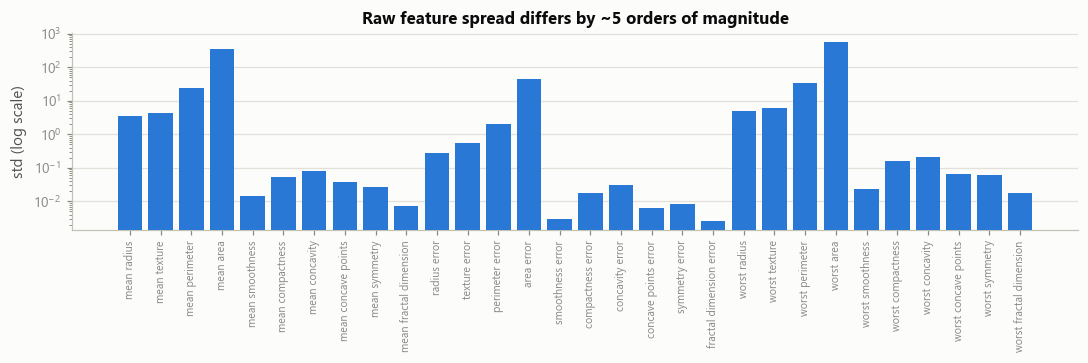

In [3]:
display(df.describe().T[["mean", "std", "min", "max"]].round(3))

# feature scales differ by orders of magnitude -> standardisation is essential
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(30), X.std(axis=0), color=H.SERIES[0], zorder=3)
ax.set_yscale("log"); ax.set_xticks(range(30)); ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
ax.set_ylabel("std (log scale)"); ax.set_title("Raw feature spread differs by ~5 orders of magnitude")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/feature_scales.png", dpi=150, bbox_inches="tight"); plt.show()

The classes are imbalanced (≈63 % benign / 37 % malignant), so the split must be **stratified** and we
report precision/recall/F1 in addition to accuracy. The raw features range from ~0.001 (e.g. fractal
dimension) to ~4000 (worst area), so without scaling the large features would dominate the weighted sums
and gradient descent would be very poorly conditioned.

## 2. Input preprocessing — train/test split and standardisation

For each split ratio we (1) split stratified so every class keeps its proportion and (2) standardise every
feature to zero mean / unit variance: $x' = (x - \mu_{train}) / \sigma_{train}$. The mean and standard
deviation are computed on the **training set only** and then applied to the test set, so the test data
stays truly unseen.

In [4]:
SPLITS = [0.30, 0.20]          # test fraction -> 70:30 and 80:20
rows = []
for ts in SPLITS:
    X_tr, X_te, y_tr, y_te, scaler = H.split_and_scale(X, y, ts)
    rows.append({"Split": H.split_name(ts), "Train samples": len(y_tr), "Test samples": len(y_te),
                 **{f"train {c}": int((y_tr == k).sum()) for k, c in enumerate(class_names)},
                 **{f"test {c}": int((y_te == k).sum()) for k, c in enumerate(class_names)},
                 "train mean after scaling": round(float(X_tr.mean()), 6),
                 "train std after scaling": round(float(X_tr.std()), 6)})
display(pd.DataFrame(rows).set_index("Split").T)

Split,70:30,80:20
Train samples,398.0,455.0
Test samples,171.0,114.0
train benign,250.0,285.0
train malignant,148.0,170.0
test benign,107.0,72.0
test malignant,64.0,42.0
train mean after scaling,-0.0,-0.0
train std after scaling,1.0,1.0


## 3. Step-by-step walk-through of one training iteration (30–8–1, 70:30 split)

This section opens up the `MLP` class and performs every step by hand with NumPy, then checks that the
class does exactly the same thing. The steps demonstrated are those required by the assignment:
**input feeding → weight & bias initialisation → forward propagation (ReLU) → sigmoid output →
binary cross-entropy loss → backpropagation → gradient calculation → gradient-descent update.**

### 3.1 Input feeding
The whole (scaled) training set is fed as one matrix $X$ of shape (samples × features); each row is one
sample. Below are the first 5 rows.

In [5]:
X_tr, X_te, y_tr, y_te, _ = H.split_and_scale(X, y, 0.30)
print("X_train shape:", X_tr.shape, "  y_train shape:", y_tr.shape)

display(pd.DataFrame(X_tr[:5, :8], columns=feature_names[:8]).round(4)
        .assign(label=[class_names[i] for i in y_tr[:5]]))
print("(only the first 8 of 30 features shown)")

X_train shape: (398, 30)   y_train shape: (398,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,label
0,1.7058,1.0497,2.1213,1.6693,2.2765,4.5443,3.5391,2.8484,malignant
1,0.5364,-0.9099,0.5691,0.3903,-0.0659,0.6449,0.3935,0.5570,malignant
2,-0.1315,-0.9933,-0.1488,-0.2115,-0.9162,-0.5086,-0.5675,-0.6066,benign
3,0.9281,1.4181,0.9254,0.8285,0.3297,0.2237,0.9832,0.4439,malignant
4,0.1447,-0.9725,0.1583,-0.0097,1.2058,0.5850,0.1377,0.5629,benign


(only the first 8 of 30 features shown)


### 3.2 Weight and bias initialisation
For layer $l$ with $n_{in}$ inputs and $n_{out}$ outputs, $W^{[l]}$ has shape $(n_{in}, n_{out})$ and
$b^{[l]}$ has shape $(1, n_{out})$.

* Hidden layers feed into ReLU, so we use **He initialisation** $W \sim \mathcal N(0,\, 2/n_{in})$, which keeps
  the variance of activations roughly constant from layer to layer.
* The output layer uses **Xavier initialisation** $W \sim \mathcal N(0,\, 1/n_{in})$.
* Biases start at **0** (the random weights already break the symmetry between neurons).

In [6]:
model = MLP([30, 8, 1], output="sigmoid", seed=42)
print(model, "| trainable parameters:", model.n_params())
for l in range(model.n_layers):
    print(f"\nW{l+1} shape {model.W[l].shape}   b{l+1} shape {model.b[l].shape}")

    if model.W[l].shape[0] <= 8:
        print(f"W{l+1} =\n{model.W[l]}")
    else:
        print(f"W{l+1} (first 5 rows of {model.W[l].shape[0]}) =\n{model.W[l][:5]}")
    print(f"b{l+1} = {model.b[l]}")

MLP(30-8-1, output=sigmoid) | trainable parameters: 257

W1 shape (30, 8)   b1 shape (1, 8)
W1 (first 5 rows of 30) =
[[ 0.0787 -0.2685  0.1938  0.2429 -0.5038 -0.3362  0.033  -0.0817]
 [-0.0043 -0.2203  0.2271  0.2008  0.017   0.2911  0.1207 -0.2219]
 [ 0.0952 -0.2476  0.2268 -0.0129 -0.0477 -0.1758  0.3157 -0.0399]
 [-0.1106 -0.0909  0.1374  0.0944  0.1066  0.1112  0.553  -0.1049]
 [-0.1323 -0.2101  0.159   0.2915 -0.0294 -0.2169 -0.2129  0.168 ]]
b1 = [[0. 0. 0. 0. 0. 0. 0. 0.]]

W2 shape (8, 1)   b2 shape (1, 1)
W2 =
[[-0.31  ]
 [-0.0333]
 [-0.6215]
 [-0.5187]
 [ 0.7528]
 [-0.4552]
 [-0.3878]
 [ 0.6494]]
b2 = [[0.]]


### 3.3 Forward propagation
$$Z^{[1]} = X W^{[1]} + b^{[1]}, \qquad A^{[1]} = \mathrm{ReLU}(Z^{[1]}) = \max(0, Z^{[1]})$$
$$Z^{[2]} = A^{[1]} W^{[2]} + b^{[2]}, \qquad \hat y = \sigma(Z^{[2]}) = \frac{1}{1 + e^{-Z^{[2]}}}$$
$\hat y_i$ is the predicted probability that sample $i$ is **malignant**; we predict malignant if $\hat y_i \ge 0.5$.

In [7]:
W1, b1, W2, b2 = model.W[0], model.b[0], model.W[1], model.b[1]
Z1 = X_tr @ W1 + b1
A1 = relu(Z1)
Z2 = A1 @ W2 + b2
P  = sigmoid(Z2)

print("Z1 (first 3 samples):\n", Z1[:3])
print("A1 = ReLU(Z1) (first 3 samples):\n", A1[:3])
print("Z2 (first 3 samples):", Z2[:3].ravel())
print("sigmoid output P(malignant) (first 3 samples):", P[:3].ravel())
print("same as model.forward():", np.allclose(P, model.forward(X_tr)[0]))

Z1 (first 3 samples):
 [[-2.1277  1.5236  3.3124  3.8339 -2.197  -1.5627 -2.7663 -5.5054]
 [ 0.623   1.6201  0.639  -0.0753 -1.1957 -0.6002  0.4903  0.2149]
 [ 0.2679  0.7308 -0.1708  0.0489  0.1227  0.3335  0.1726 -0.1275]]
A1 = ReLU(Z1) (first 3 samples):
 [[0.     1.5236 3.3124 3.8339 0.     0.     0.     0.    ]
 [0.623  1.6201 0.639  0.     0.     0.     0.4903 0.2149]
 [0.2679 0.7308 0.     0.0489 0.1227 0.3335 0.1726 0.    ]]
Z2 (first 3 samples): [-4.0978 -0.6948 -0.2591]
sigmoid output P(malignant) (first 3 samples): [0.0163 0.333  0.4356]
same as model.forward(): True


### 3.4 Binary cross-entropy loss
$$L = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i\log\hat y_i + (1-y_i)\log(1-\hat y_i)\Big]$$
For reference, a network that outputs 0.5 for every sample scores $\ln 2 \approx 0.693$. With random
initial weights the first loss is usually somewhat higher, because some predictions are confidently wrong.

In [8]:
Y_tr = y_tr.reshape(-1, 1).astype(float)
loss0 = binary_cross_entropy(Y_tr, P)
print(f"initial loss = {loss0:.4f}   (ln 2 = {np.log(2):.4f})")

initial loss = 1.2833   (ln 2 = 0.6931)


### 3.5 Backpropagation and gradient calculation
Applying the chain rule from the loss back to every parameter. For sigmoid + binary cross-entropy the derivative of the loss with respect to the output pre-activation simplifies to

$$dZ^{[2]} = \frac{\partial L}{\partial Z^{[2]}} = \frac{1}{m}(\hat Y - Y)$$

and then

$$dW^{[2]} = A^{[1]\top} dZ^{[2]}, \qquad db^{[2]} = \textstyle\sum_i dZ^{[2]}_i$$
$$dA^{[1]} = dZ^{[2]} W^{[2]\top}, \qquad dZ^{[1]} = dA^{[1]} \odot \mathrm{ReLU}'(Z^{[1]}), \quad \mathrm{ReLU}'(z)=\begin{cases}1 & z>0\\0 & z\le 0\end{cases}$$
$$dW^{[1]} = X^{\top} dZ^{[1]}, \qquad db^{[1]} = \textstyle\sum_i dZ^{[1]}_i$$

Each gradient has exactly the same shape as the parameter it updates.

In [9]:
m = X_tr.shape[0]
dZ2 = (P - Y_tr) / m
dW2 = A1.T @ dZ2
db2 = dZ2.sum(axis=0, keepdims=True)
dA1 = dZ2 @ W2.T
dZ1 = dA1 * relu_derivative(Z1)
dW1 = X_tr.T @ dZ1
db1 = dZ1.sum(axis=0, keepdims=True)

for name, g in [("dW1", dW1), ("db1", db1), ("dW2", dW2), ("db2", db2)]:
    print(f"{name} shape {g.shape}")
print("\ndW2 =\n", dW2)
print("db2 =", db2)

# the class's backward() must give identical gradients
_, cache = model.forward(X_tr)
dW_cls, db_cls = model.backward(Y_tr, cache)
print("\nmanual gradients == model.backward():",
      all(np.allclose(a, b) for a, b in zip([dW1, dW2, db1, db2], dW_cls + db_cls)))

dW1 shape (30, 8)
db1 shape (1, 8)
dW2 shape (8, 1)
db2 shape (1, 1)

dW2 =
 [[ 0.0159]
 [-0.2452]
 [-0.3787]
 [-0.1652]
 [ 0.411 ]
 [ 0.1683]
 [-0.1248]
 [ 0.1838]]
db2 = [[0.1085]]

manual gradients == model.backward(): True


**Gradient check.** To prove the backprop equations are implemented correctly, every analytical gradient
is compared with a numerical estimate $\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}$
(on a small batch). A relative error below $10^{-7}$ means the two agree.

In [10]:
check = gradient_check(MLP([30, 8, 1], output="sigmoid", seed=0), X_tr[:20], y_tr[:20])
display(pd.DataFrame(check, columns=["parameter", "shape", "relative error"]))

,parameter,shape,relative error
0,W1,"(30, 8)",6.1361e-11
1,b1,"(1, 8)",2.5680e-11
2,W2,"(8, 1)",1.3138e-11
3,b2,"(1, 1)",1.0797e-11


### 3.6 Weight and bias update (gradient descent)
$$W^{[l]} \leftarrow W^{[l]} - \eta\, dW^{[l]}, \qquad b^{[l]} \leftarrow b^{[l]} - \eta\, db^{[l]}$$
Below: one update step, after which the loss must decrease. Training (section 4) simply repeats
*forward → loss → backward → update* for every epoch.

In [11]:
lr = 0.05
W2_before = model.W[1].copy()
model.update(dW_cls, db_cls, lr)
loss1 = model.compute_loss(Y_tr, model.forward(X_tr)[0])
print(f"loss before update: {loss0:.6f}")
print(f"loss after  update: {loss1:.6f}   (decreased: {loss1 < loss0})")
print("\nW2 change after one step (= -lr * dW2):\n", model.W[1] - W2_before)

loss before update: 1.283328
loss after  update: 1.130485   (decreased: True)

W2 change after one step (= -lr * dW2):
 [[-0.0008]
 [ 0.0123]
 [ 0.0189]
 [ 0.0083]
 [-0.0206]
 [-0.0084]
 [ 0.0062]
 [-0.0092]]


## 4. Training the six experiments

3 architectures × 2 split ratios. Every model starts from the same seed (42) and is trained with
full-batch gradient descent, learning rate **0.05**, **1000 epochs**. Test loss is also recorded every
epoch (it is *not* used for training, only for the plots).

In [12]:
ARCHS  = [[30, 8, 1], [30, 15, 1], [30, 25, 1]]
LR, EPOCHS = 0.05, 1000

results = []
for ts in SPLITS:
    for arch in ARCHS:
        r = H.run_experiment(X, y, arch, "sigmoid", ts, lr=LR, epochs=EPOCHS)
        results.append(r)
        h = r["model"].history["train_loss"]
        print(f"{r['arch']:>8} | {r['split']} | loss {h[0]:.4f} -> {h[-1]:.4f} | "
              f"train acc {r['train']['accuracy']:.4f} | test acc {r['test']['accuracy']:.4f}")

  30-8-1 | 70:30 | loss 1.2833 -> 0.0430 | train acc 0.9925 | test acc 0.9708


 30-15-1 | 70:30 | loss 1.2140 -> 0.0473 | train acc 0.9874 | test acc 0.9825


 30-25-1 | 70:30 | loss 1.7249 -> 0.0486 | train acc 0.9849 | test acc 0.9883


  30-8-1 | 80:20 | loss 1.3130 -> 0.0423 | train acc 0.9934 | test acc 0.9825


 30-15-1 | 80:20 | loss 1.2167 -> 0.0467 | train acc 0.9868 | test acc 0.9737


 30-25-1 | 80:20 | loss 1.7249 -> 0.0477 | train acc 0.9868 | test acc 0.9825


## 5. Performance metrics table (test set)

**Malignant is the positive class (label 1)**, so *recall* = fraction of malignant tumours that were caught (sensitivity) and *precision* = fraction of 'malignant' predictions that were correct. sklearn stores 0 = malignant, so labels are flipped in `helpers.load_data`.

In [13]:
table = H.metrics_table(results)
table.to_csv(f"{OUT_DIR}/metrics_table.csv")
display(H.format_table(table))

,Architecture,Split,Train / Test,Params,Final train loss,Train acc,Test acc,Precision,Recall,F1-score
Exp,,,,,,,,,,
1,30-8-1,70:30,398 / 171,257,0.0430,0.9925,0.9708,1.0000,0.9219,0.9593
2,30-15-1,70:30,398 / 171,481,0.0473,0.9874,0.9825,1.0000,0.9531,0.9760
3,30-25-1,70:30,398 / 171,801,0.0486,0.9849,0.9883,1.0000,0.9688,0.9841
4,30-8-1,80:20,455 / 114,257,0.0423,0.9934,0.9825,1.0000,0.9524,0.9756
5,30-15-1,80:20,455 / 114,481,0.0467,0.9868,0.9737,1.0000,0.9286,0.9630
6,30-25-1,80:20,455 / 114,801,0.0477,0.9868,0.9825,1.0000,0.9524,0.9756


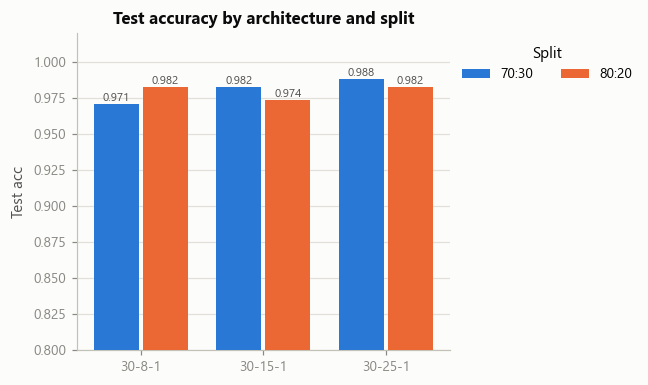

In [14]:
H.plot_metric_bars(table, "Test acc", "Test accuracy by architecture and split",
                   save=f"{OUT_DIR}/test_accuracy_bars.png", ylim=(0.8, 1.02)); plt.show()

**Per-class report for every experiment** (test set):

In [15]:
from sklearn.metrics import classification_report
for i, r in enumerate(results, 1):
    print(f"=== Exp {i}: {r['arch']}  ({r['split']}) ===")
    print(classification_report(r["y_test"], r["y_pred_test"], target_names=class_names, digits=4))

=== Exp 1: 30-8-1  (70:30) ===
              precision    recall  f1-score   support

      benign     0.9554    1.0000    0.9772       107
   malignant     1.0000    0.9219    0.9593        64

    accuracy                         0.9708       171
   macro avg     0.9777    0.9609    0.9683       171
weighted avg     0.9721    0.9708    0.9705       171

=== Exp 2: 30-15-1  (70:30) ===
              precision    recall  f1-score   support

      benign     0.9727    1.0000    0.9862       107
   malignant     1.0000    0.9531    0.9760        64

    accuracy                         0.9825       171
   macro avg     0.9864    0.9766    0.9811       171
weighted avg     0.9829    0.9825    0.9824       171

=== Exp 3: 30-25-1  (70:30) ===
              precision    recall  f1-score   support

      benign     0.9817    1.0000    0.9907       107
   malignant     1.0000    0.9688    0.9841        64

    accuracy                         0.9883       171
   macro avg     0.9908    0.9844

## 6. Confusion matrices (test set)
Rows = actual class, columns = predicted class; the diagonal holds the correct predictions.

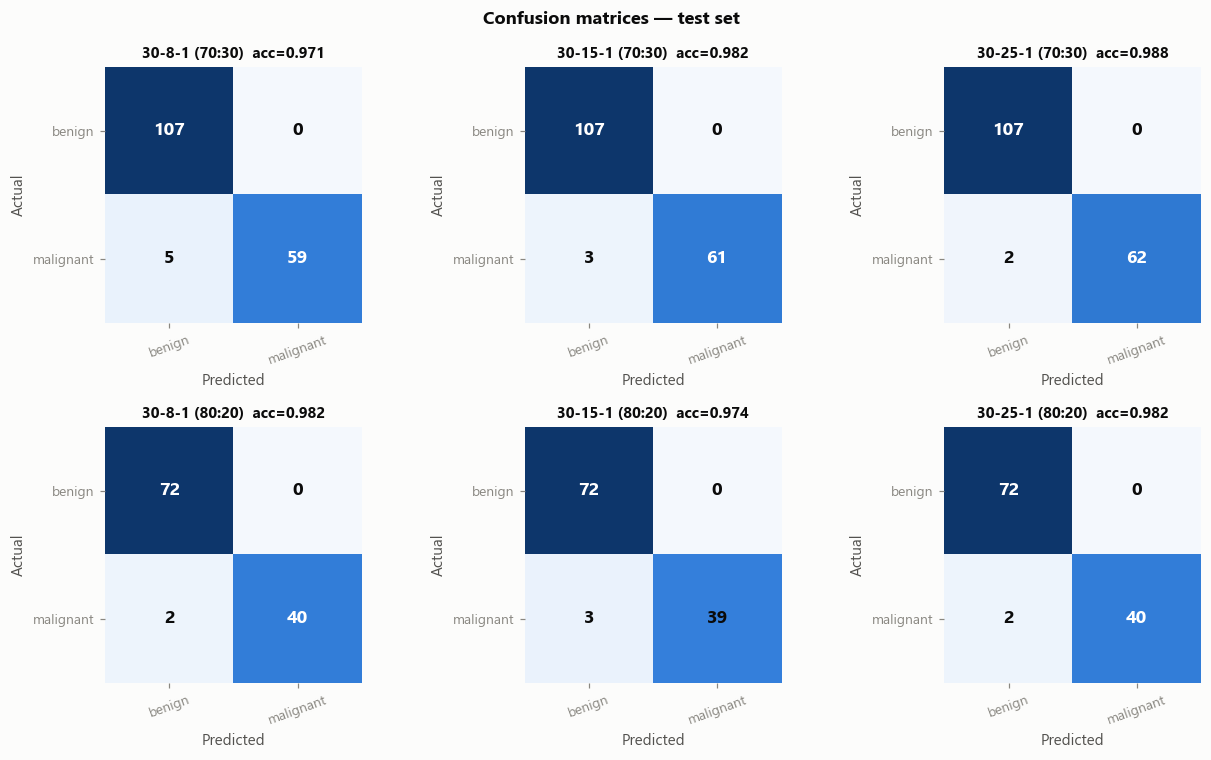

Exp 1 30-8-1 (70:30):


,pred benign,pred malignant
actual benign,107,0
actual malignant,5,59


Exp 2 30-15-1 (70:30):


,pred benign,pred malignant
actual benign,107,0
actual malignant,3,61


Exp 3 30-25-1 (70:30):


,pred benign,pred malignant
actual benign,107,0
actual malignant,2,62


... (2 outputs left out)

Exp 5 30-15-1 (80:20):


,pred benign,pred malignant
actual benign,72,0
actual malignant,3,39


Exp 6 30-25-1 (80:20):


,pred benign,pred malignant
actual benign,72,0
actual malignant,2,40


In [16]:
H.plot_confusion_matrices(results, class_names, "Confusion matrices — test set",
                          save=f"{OUT_DIR}/confusion_matrices.png"); plt.show()
for i, r in enumerate(results, 1):
    print(f"Exp {i} {r['arch']} ({r['split']}):")
    display(pd.DataFrame(r["test"]["cm"], index=[f"actual {c}" for c in class_names],
                         columns=[f"pred {c}" for c in class_names]))

## 7. Training loss curves
Log scale on the y-axis so both the fast initial drop and the slow later convergence are visible.

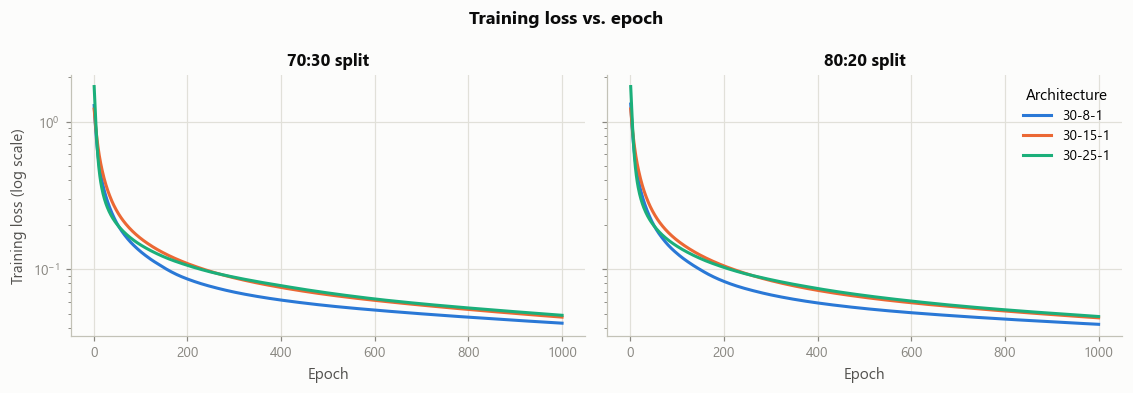

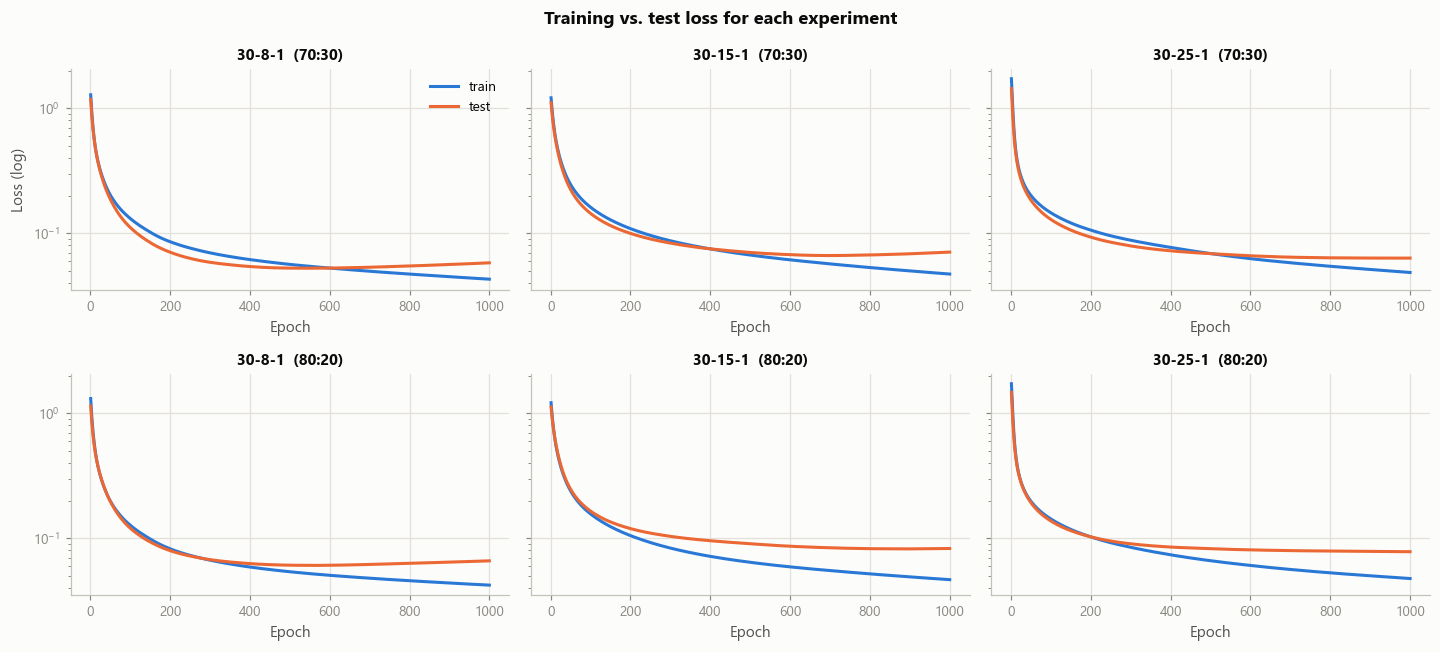

In [17]:
H.plot_loss_by_split(results, "Training loss vs. epoch", save=f"{OUT_DIR}/loss_curves.png"); plt.show()
H.plot_train_test_loss(results, "Training vs. test loss for each experiment",
                       save=f"{OUT_DIR}/train_vs_test_loss.png"); plt.show()

## 8. Initial vs. updated weight matrices

To demonstrate learning, the weights are stored right after initialisation (`model.W_init`) and compared
with the weights after training. First the full matrices for each experiment, then heatmaps
(blue = positive, red = negative, grey ≈ 0) and a summary of how much each layer changed.

In [18]:
short = [f.replace("mean ", "m.").replace("worst ", "w.").replace(" error", " err") for f in feature_names]
for i, r in enumerate(results, 1):
    m = r["model"]
    display(Markdown(f"#### Exp {i}: {r['arch']} ({r['split']})"))
    for l in range(m.n_layers):
        init_df, final_df = H.weights_as_frames(m, l, in_labels=short if l == 0 else None)
        if l == 1:   # hidden -> output weights are a single column: show side by side
            display(pd.concat([init_df.add_suffix(" initial"), final_df.add_suffix(" trained")], axis=1).T)
        else:
            print(f"W{l+1} — initial {m.W[l].shape}"); display(init_df)
            print(f"W{l+1} — after training"); display(final_df)
        print(f"b{l+1} — after training: {m.b[l].round(3)}\n")

#### Exp 1: 30-8-1 (70:30)

W1 — initial (30, 8)


,h1,h2,h3,h4,h5,h6,h7,h8
m.radius,0.079,-0.269,0.194,0.243,-0.504,-0.336,0.033,-0.082
m.texture,-0.004,-0.220,0.227,0.201,0.017,0.291,0.121,-0.222
m.perimeter,0.095,-0.248,0.227,-0.013,-0.048,-0.176,0.316,-0.040
m.area,-0.111,-0.091,0.137,0.094,0.107,0.111,0.553,-0.105
m.smoothness,-0.132,-0.210,0.159,0.291,-0.029,-0.217,-0.213,0.168
m.compactness,0.192,0.140,-0.172,0.060,0.030,0.056,0.225,0.058
m.concavity,0.175,0.017,0.075,0.163,-0.376,-0.083,-0.121,-0.165
m.concave points,-0.071,0.386,-0.224,0.250,-0.435,-0.086,0.042,0.151
m.symmetry,0.184,0.205,-0.090,-0.119,0.222,-0.049,-0.329,-0.293
m.fractal dimension,-0.237,0.128,0.037,0.178,-0.110,0.041,0.162,-0.080


W1 — after training


,h1,h2,h3,h4,h5,h6,h7,h8
m.radius,-0.019,-0.210,0.043,0.087,-0.267,-0.477,-0.126,0.150
m.texture,-0.176,-0.100,-0.037,0.073,0.256,0.146,-0.154,0.258
m.perimeter,0.001,-0.184,0.078,-0.172,0.192,-0.311,0.163,0.191
m.area,-0.217,-0.028,-0.027,-0.076,0.335,-0.075,0.389,0.120
m.smoothness,-0.112,-0.132,0.191,0.213,0.044,-0.222,-0.094,0.255
m.compactness,0.217,0.203,-0.181,0.025,0.183,0.171,0.244,0.162
m.concavity,0.088,0.133,-0.035,-0.025,-0.180,-0.205,-0.211,0.093
m.concave points,-0.163,0.507,-0.365,0.025,-0.195,-0.276,-0.040,0.405
m.symmetry,0.228,0.294,-0.083,-0.203,0.148,0.014,-0.316,-0.095
m.fractal dimension,-0.210,0.138,0.082,0.238,-0.169,0.099,0.263,-0.159


b1 — after training: [[ 0.112 -0.037  0.079  0.222 -0.13   0.613  0.052  0.243]]



... (38 outputs left out)

,h1,h2,h3,h4,h5,h6,h7,h8,h9,h10,h11,h12,h13,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23,h24,h25
m.radius,0.157,-0.236,0.152,0.358,-0.501,-0.204,-0.106,-0.014,-0.011,-0.242,0.262,0.207,0.053,0.305,0.233,-0.386,0.095,-0.277,0.158,0.030,-0.066,-0.105,0.298,0.013,-0.117
m.texture,-0.002,0.184,0.064,0.139,0.118,0.581,-0.296,0.009,-0.293,0.113,0.335,-0.009,-0.207,-0.234,0.419,-0.123,0.138,-0.205,-0.020,0.041,0.083,0.243,0.034,0.202,0.028
m.perimeter,0.149,0.194,-0.417,0.033,-0.114,-0.035,-0.205,0.449,-0.228,0.231,-0.402,-0.080,0.074,0.167,0.288,0.046,-0.090,-0.149,0.155,-0.006,-0.339,-0.222,-0.254,0.181,0.029
m.area,0.249,-0.080,0.004,0.279,-0.078,0.234,-0.319,-0.035,-0.116,-0.330,0.157,-0.113,0.043,0.135,0.216,-0.019,-0.027,-0.137,-0.093,-0.397,-0.408,-0.279,-0.278,0.154,-0.240
m.smoothness,-0.039,0.344,-0.096,0.249,-0.230,0.078,-0.302,-0.045,0.219,-0.436,0.127,0.076,-0.081,-0.363,0.123,0.018,0.058,-0.017,0.411,-0.048,-0.293,0.083,0.076,0.360,0.216
m.compactness,0.079,0.363,-0.317,-0.096,-0.153,-0.060,-0.343,0.134,0.008,-0.362,-0.277,0.075,0.183,0.548,0.707,0.241,-0.248,-0.556,0.072,-0.173,0.045,-0.127,-0.017,0.289,0.003
m.concavity,-0.015,-0.243,-0.455,0.016,0.028,0.543,-0.052,0.273,-0.157,-0.315,-0.223,-0.174,0.559,-0.197,0.295,-0.412,0.243,0.077,-0.095,0.021,-0.132,0.175,-0.135,-0.258,-0.333
m.concave points,0.114,0.442,0.004,0.122,0.088,0.476,-0.085,-0.053,0.246,0.094,0.441,0.062,-0.268,-0.343,0.545,0.301,-0.047,-0.134,0.308,-0.249,-0.248,0.238,-0.119,0.063,-0.038
m.symmetry,0.087,0.350,0.019,0.170,-0.488,0.074,-0.266,-0.247,-0.221,-0.073,0.210,-0.340,-0.004,-0.114,-0.084,0.381,0.142,0.349,-0.039,-0.160,-0.050,0.084,0.066,-0.254,0.010
m.fractal dimension,-0.046,0.599,0.516,-0.235,-0.003,-0.459,-0.022,0.000,0.312,-0.170,-0.178,-0.551,-0.084,-0.264,-0.266,-0.055,-0.017,-0.441,-0.335,0.544,-0.244,-0.314,0.502,0.715,-0.318


b1 — after training: [[ 0.078  0.006 -0.017 -0.124 -0.04   0.076  0.227  0.111  0.136  0.006  0.025 -0.01  -0.011 -0.003  0.182  0.441  0.005  0.005  0.031
  -0.05   0.105 -0.033  0.037 -0.035  0.034]]



,h1,h2,h3,h4,h5,h6,h7,h8,h9,h10,h11,h12,h13,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23,h24,h25
out1 initial,0.002,-0.060,-0.203,0.410,0.357,0.227,-0.184,0.171,0.128,0.089,0.250,0.127,0.148,0.127,0.068,-0.357,0.017,-0.111,-0.256,0.336,0.346,0.272,0.051,0.270,0.002
out1 trained,0.464,0.277,0.010,0.438,-0.242,0.564,-0.776,0.594,-0.470,-0.043,0.336,0.143,0.263,-0.228,1.046,-1.189,-0.022,-0.180,-0.223,-0.055,-0.755,0.202,-0.151,0.169,0.311


b2 — after training: [[-0.249]]



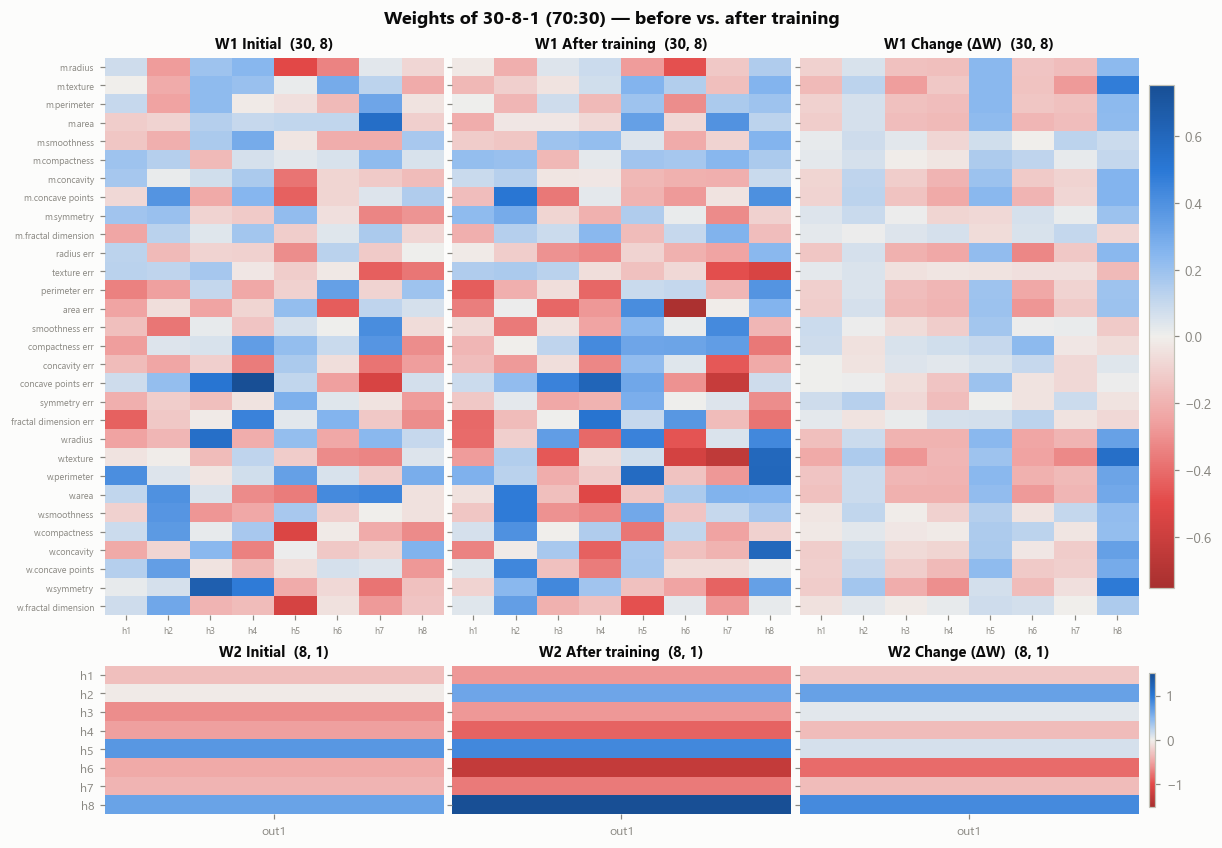

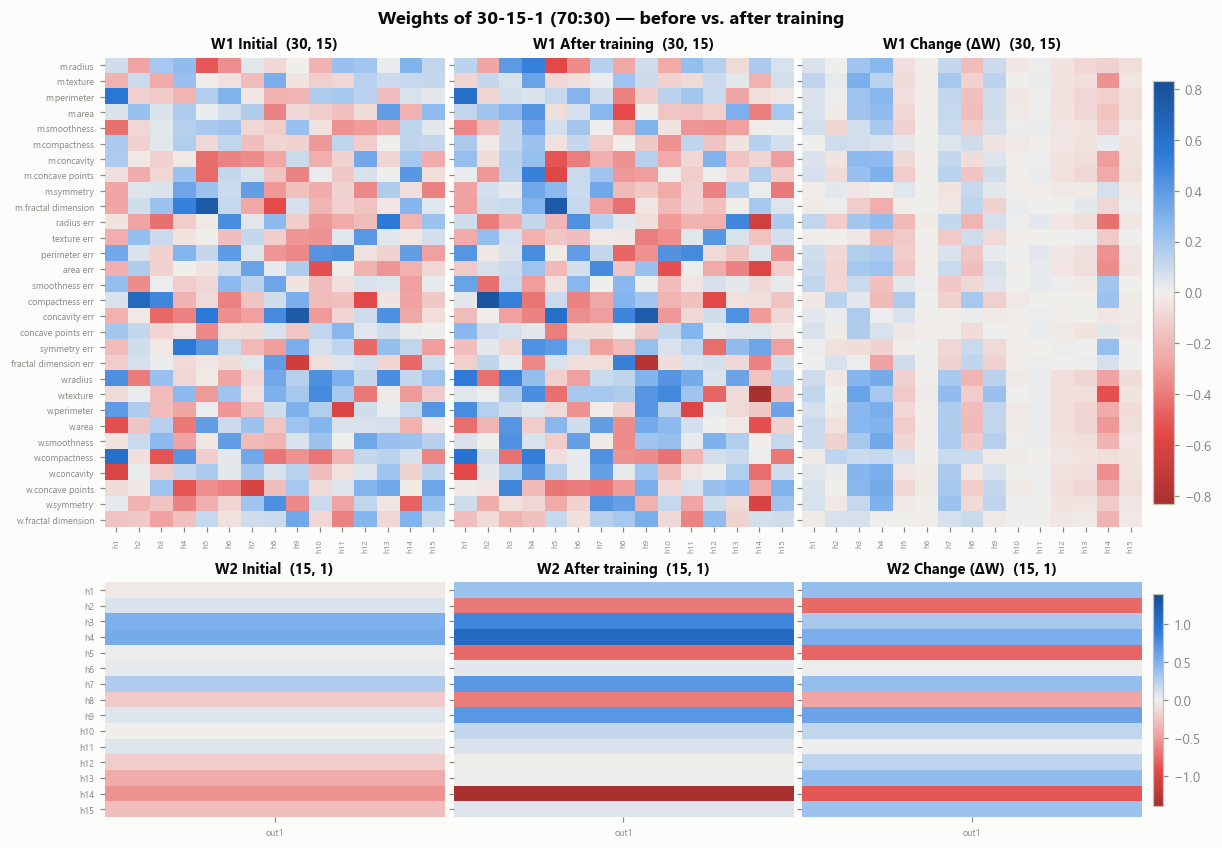

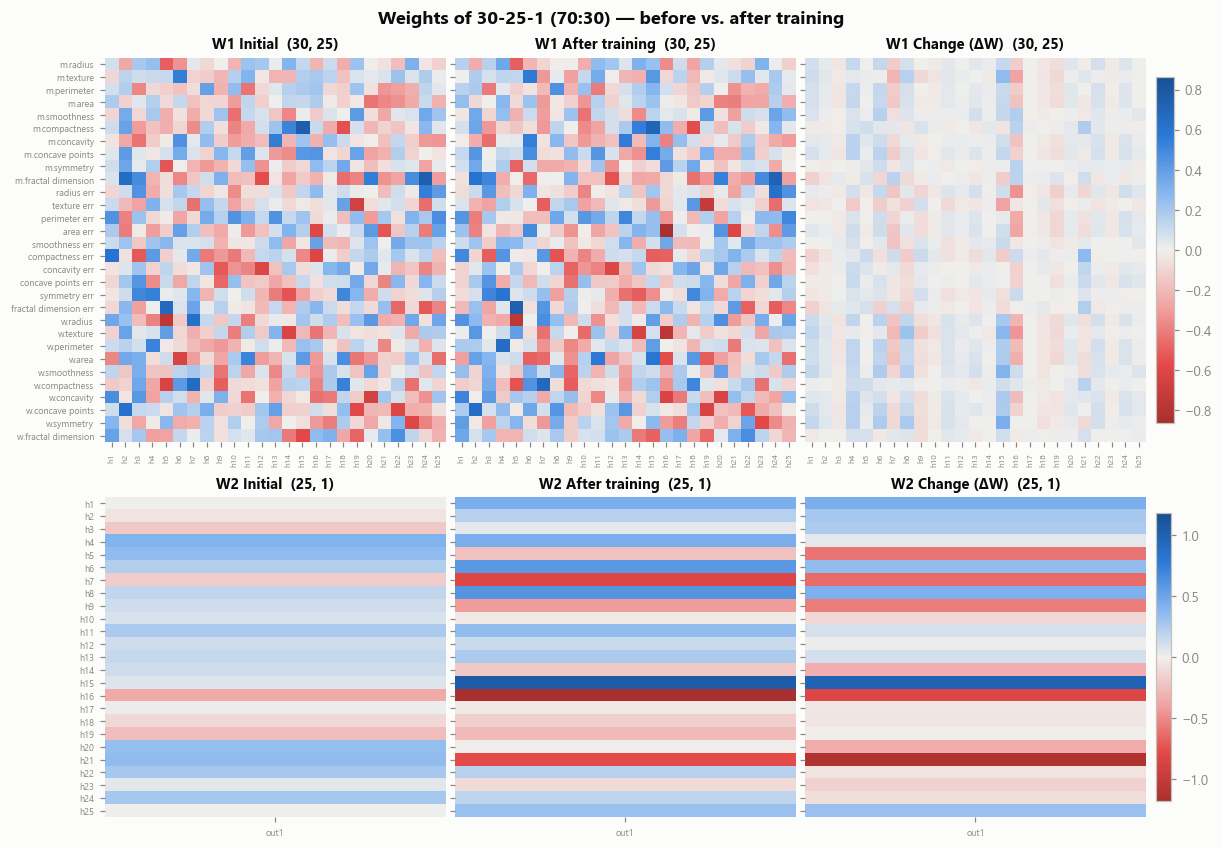

In [19]:
for r in results[:3]:      # one heatmap per architecture (70:30 split)
    H.plot_weights(r["model"], f"Weights of {r['arch']} ({r['split']}) — before vs. after training",
                   in_labels=feature_names if X.shape[1] <= 8 else short,
                   save=f"{OUT_DIR}/weights_{r['arch']}.png"); plt.show()

In [20]:
wc = H.weight_change_table(results)
wc.to_csv(f"{OUT_DIR}/weight_change.csv", index=False)
display(H.format_table(wc))

,Architecture,Split,Layer,||W_init||,||W_final||,||ΔW||,mean |ΔW|,||b_final||
0,30-8-1,70:30,"W1 (30, 8)",3.6000,4.1638,2.4229,0.1268,0.7237
1,30-8-1,70:30,"W2 (8, 1)",1.4486,2.6373,1.4700,0.4321,0.1069
2,30-15-1,70:30,"W1 (30, 15)",5.2141,5.6365,2.5325,0.0826,0.6753
3,30-15-1,70:30,"W2 (15, 1)",1.1296,2.5085,1.8825,0.4181,0.1852
4,30-25-1,70:30,"W1 (30, 25)",6.9654,7.2554,1.9942,0.0498,0.5894
5,30-25-1,70:30,"W2 (25, 1)",1.0900,2.3853,2.2398,0.3298,0.2858
6,30-8-1,80:20,"W1 (30, 8)",3.6000,4.1562,2.4155,0.1266,0.7197
7,30-8-1,80:20,"W2 (8, 1)",1.4486,2.6240,1.4712,0.4328,0.0778
8,30-15-1,80:20,"W1 (30, 15)",5.2141,5.6317,2.4976,0.0815,0.6733
9,30-15-1,80:20,"W2 (15, 1)",1.1296,2.4971,1.8818,0.4218,0.1526


## 9. Extension — deeper networks with 2–5 hidden layers (still from scratch)

The `MLP` class accepts any list of layer sizes, so the exact same NumPy code (same forward/backward
equations, applied layer by layer) is used for deeper networks. Hidden widths taper towards the output.
Hyperparameters are unchanged (lr = 0.05, 1000 epochs) so the comparison with the 1-hidden-layer
networks is fair.

In [21]:
DEEP_ARCHS = [[30, 15, 8, 1], [30, 25, 15, 8, 1], [30, 25, 15, 8, 4, 1], [30, 32, 25, 15, 8, 4, 1]]
gc = gradient_check(MLP(DEEP_ARCHS[-1], output="sigmoid", seed=0), X_tr[:15], y_tr[:15])
print("gradient check on the 5-hidden-layer net, max relative error:", max(e for *_, e in gc))

deep_results = []
for ts in SPLITS:
    for arch in DEEP_ARCHS:
        r = H.run_experiment(X, y, arch, "sigmoid", ts, lr=0.05, epochs=1000)
        deep_results.append(r)
deep_table = H.metrics_table(deep_results)
deep_table.insert(1, "Hidden layers", [len(a) - 2 for a in DEEP_ARCHS] * len(SPLITS))
deep_table.to_csv(f"{OUT_DIR}/deep_metrics_table.csv")
display(H.format_table(deep_table))

gradient check on the 5-hidden-layer net, max relative error: 2.2533287036931989e-10


,Architecture,Hidden layers,Split,Train / Test,Params,Final train loss,Train acc,Test acc,Precision,Recall,F1-score
Exp,,,,,,,,,,,
1,30-15-8-1,2,70:30,398 / 171,602,0.0224,0.9925,0.9825,1.0000,0.9531,0.9760
2,30-25-15-8-1,3,70:30,398 / 171,1302,0.0083,1.0000,0.9766,1.0000,0.9375,0.9677
3,30-25-15-8-4-1,4,70:30,398 / 171,1334,0.0259,0.9950,0.9649,1.0000,0.9062,0.9508
4,30-32-25-15-8-4-1,5,70:30,398 / 171,2376,0.0016,1.0000,0.9708,0.9683,0.9531,0.9606
5,30-15-8-1,2,80:20,455 / 114,602,0.0232,0.9912,0.9912,1.0000,0.9762,0.9880
6,30-25-15-8-1,3,80:20,455 / 114,1302,0.0092,1.0000,0.9649,1.0000,0.9048,0.9500
7,30-25-15-8-4-1,4,80:20,455 / 114,1334,0.0248,0.9956,0.9561,0.9744,0.9048,0.9383
8,30-32-25-15-8-4-1,5,80:20,455 / 114,2376,0.0086,0.9956,0.9649,0.9524,0.9524,0.9524


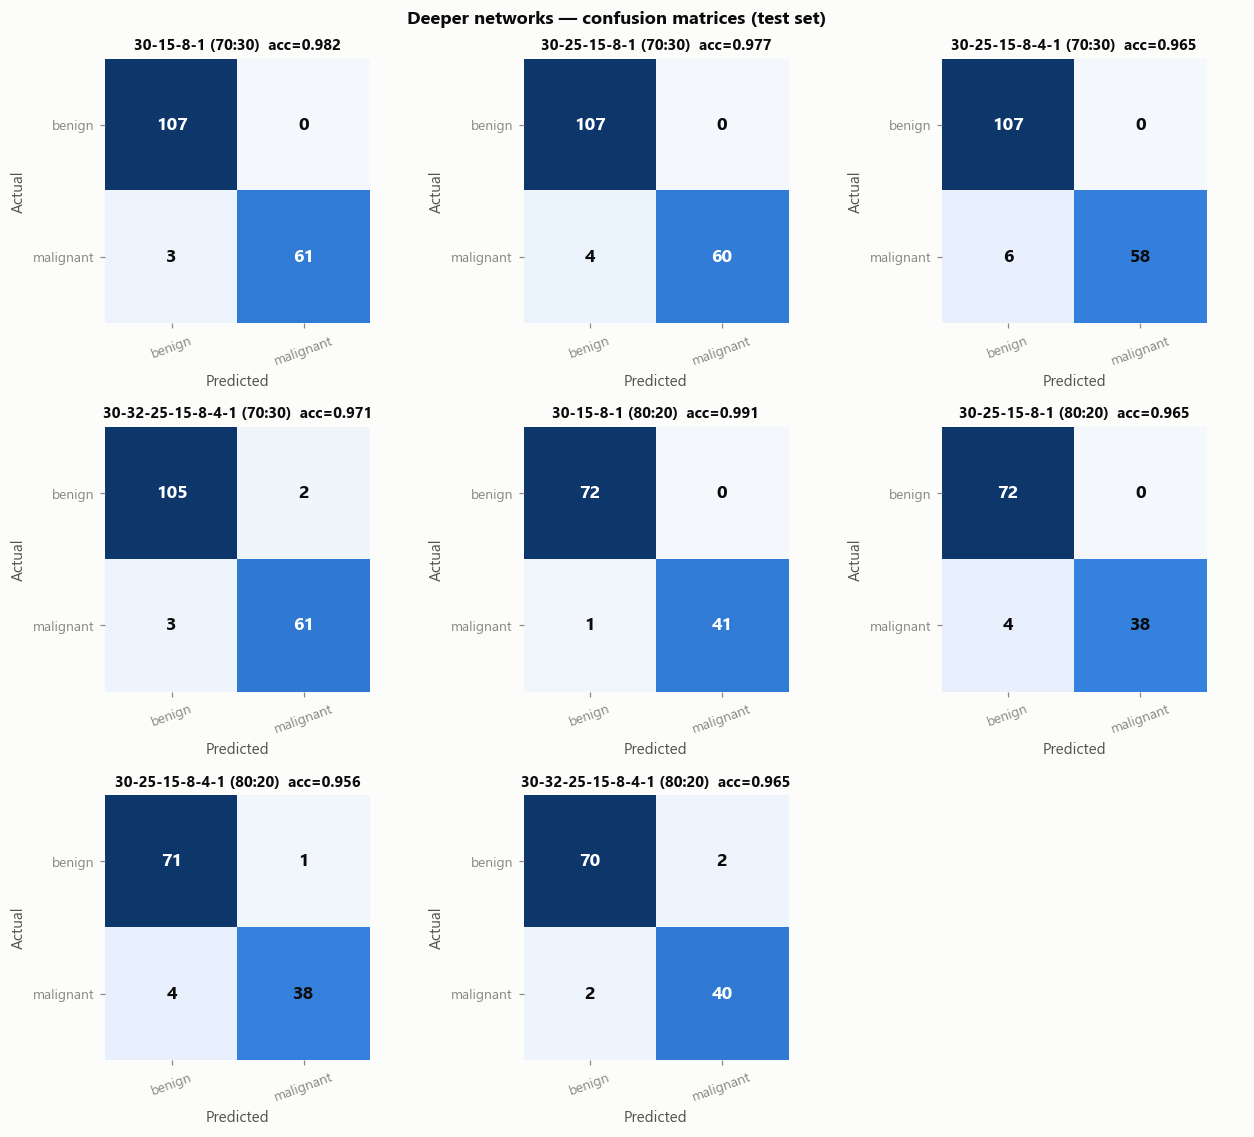

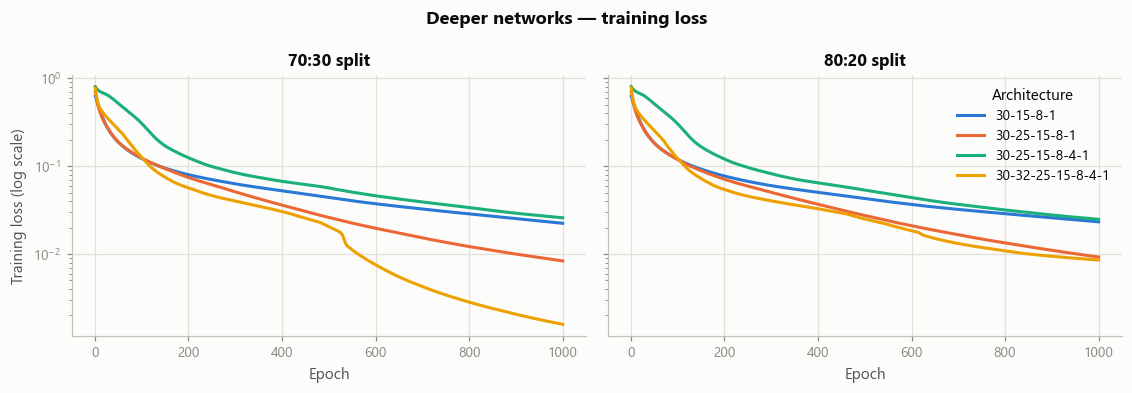

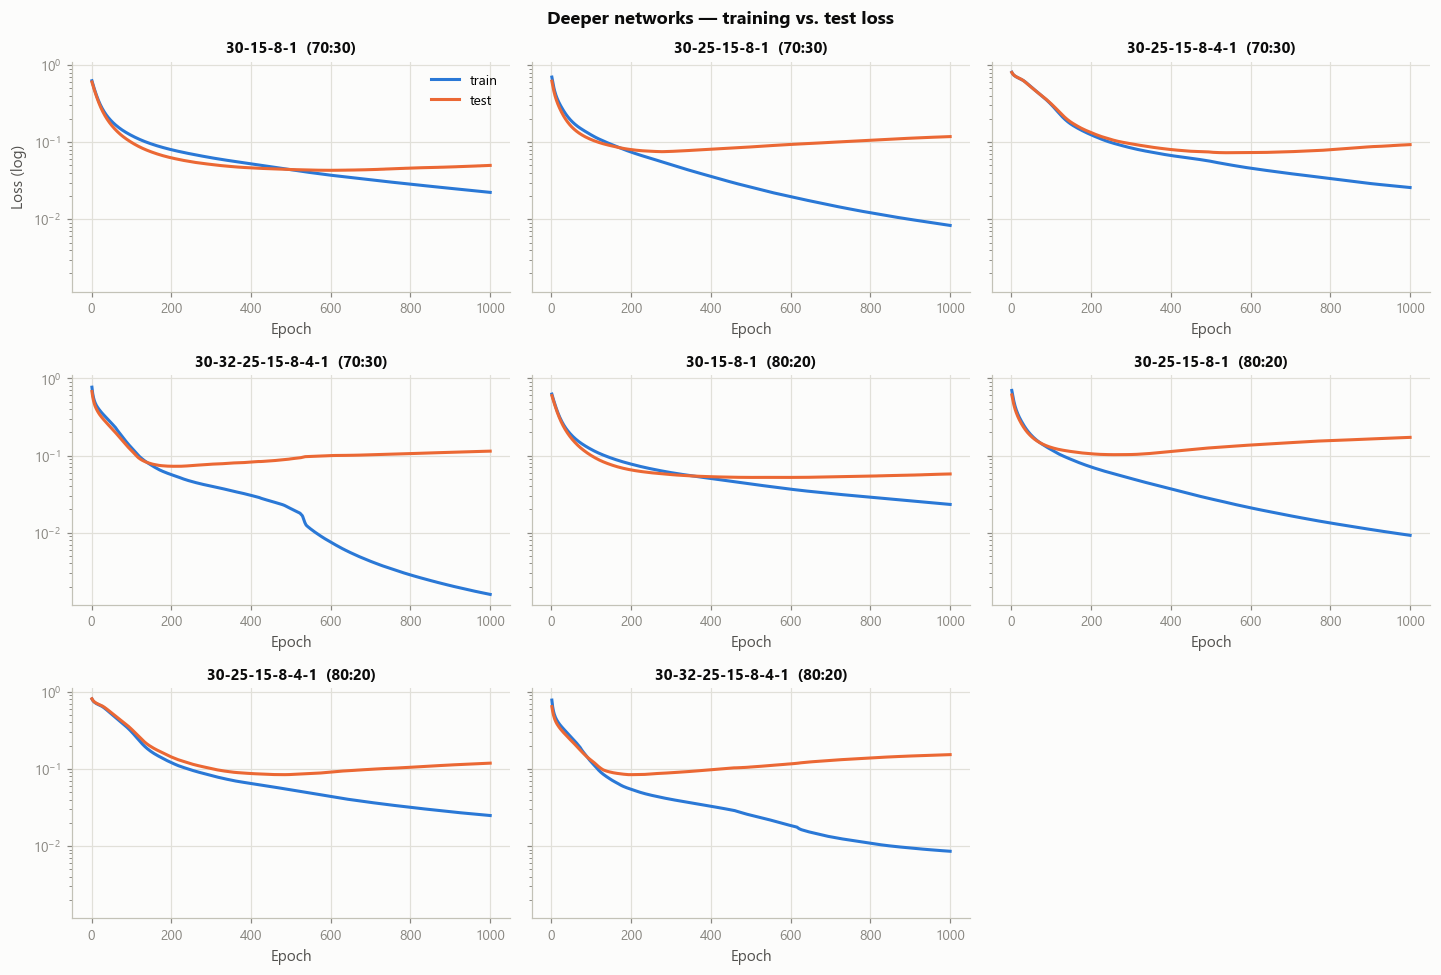

In [22]:
H.plot_confusion_matrices(deep_results, class_names, "Deeper networks — confusion matrices (test set)",
                          save=f"{OUT_DIR}/deep_confusion_matrices.png"); plt.show()
H.plot_loss_by_split(deep_results, "Deeper networks — training loss",
                     save=f"{OUT_DIR}/deep_loss_curves.png"); plt.show()
H.plot_train_test_loss(deep_results, "Deeper networks — training vs. test loss",
                       save=f"{OUT_DIR}/deep_train_vs_test_loss.png"); plt.show()

## 10. Discussion

### Summary of the six experiments (test set)

| Split | 30–8–1 | 30–15–1 | 30–25–1 |
|---|---|---|---|
| 70:30 (171 test samples): accuracy / recall | 97.08 % / 0.922 | 98.25 % / 0.953 | 98.83 % / 0.969 |
| 80:20 (114 test samples): accuracy / recall | 98.25 % / 0.952 | 97.37 % / 0.929 | 98.25 % / 0.952 |

**The network learns.** The binary cross-entropy starts at 1.2–1.7, above the ln 2 ≈ 0.69 that a
network outputting 0.5 for everything would score, because the random weights make some confidently wrong
predictions. It falls to ≈0.045 after 1000 epochs. Training accuracy reaches ≈99 % and test accuracy
97–99 %. The hidden-to-output weights change the most: for 30–8–1 the norm of W2 grows from 1.45 to 2.64,
and the network learns which hidden features vote for "malignant" and which for "benign" (heatmaps in
section 8).

**Precision is 1.000 in all six experiments.** The network never labelled a benign tumour as malignant.
Every error is a **missed malignant tumour (false negative)**, so recall (0.92–0.97) is the metric to watch
in a medical setting.

### Effect of hidden-layer size

* At 70:30, accuracy and recall increase with width (97.1 → 98.2 → 98.8 %; recall 0.92 → 0.95 → 0.97).
  The wider networks miss fewer malignant tumours (5 → 3 → 2).
* At 80:20 there is no such trend (98.2 → 97.4 → 98.2 %), so the effect of width is small. The 30
  features are highly informative, and the classes are close to linearly separable once standardised, so
  8 hidden ReLU neurons already give enough capacity. Going to 25 multiplies the parameter count by about
  3 (257 → 801) for at most 1–2 extra correct predictions.
* With more hidden neurons the learning is spread out. The mean absolute change of a W1 weight drops from
  0.127 (8 neurons) to 0.083 (15) to 0.050 (25).
* **Deeper networks** (section 9) drive the training loss down to ≈0.002–0.02 and reach 99–100 % training
  accuracy, but they do **not** generalise better (95.6–99.1 % test accuracy). The 4-hidden-layer networks
  are the weakest (96.5 % and 95.6 %). With only ~400–450 training samples, extra depth mostly adds
  overfitting capacity.

### Effect of the training-data proportion

* The two splits give similar results (97–99 % in both). 80:20 is better for 30–8–1 (+1.2 pp), worse for
  30–15–1 (−0.9 pp) and slightly worse for 30–25–1 (−0.6 pp).
* The dataset is reasonably large (569 samples), so even 70 % (398 samples) already holds enough
  examples to learn the decision boundary. The extra 57 training samples at 80:20 add little.
* The 80:20 test set is smaller (114 vs. 171 samples), so each error costs 0.88 % instead of 0.58 %, and
  the 80:20 figures are less precise estimates.
* The train-vs-test loss curves (section 7) show that for 30–8–1 and 30–15–1 the test loss bottoms out after
  ≈500–700 epochs and then creeps up while the training loss keeps decreasing, which is mild overfitting.
  For 30–25–1 it flattens instead.

### Conclusion
A from-scratch MLP with one hidden layer of 8–25 ReLU neurons and a sigmoid output detects malignant
tumours with 97–99 % test accuracy and perfect precision. A wider hidden layer slightly improves recall on
the 70:30 split. A larger training share brings no consistent improvement on this dataset.